In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

np.random.seed(42)

In [ ]:
T = 0.5                             #Time to maturity in years (6 months)
dt= 1/252                           #Time step (daily)
N_steps = int(T/dt)
N_simulations = 5_000

S0 = 50                             #Initial asset price
mu_S = 0.05                         #Expected annual return of asset
sigma_S = 0.25                      #Annual volatility of asset

F0 = 50                             #Future price of asset at t=0
mu_F = 0.05                         #Expected annual return of futures
sigma_F = 0.25                      #Annual volatility of futures

rho_SF = 0.9                        #Correlation between asset and futures price shock

Q = 5000                            # Quantity of asset
q = 50                              #Contract size of futures
transaction_cost = 0.001            #Transaction cost per unit

In [3]:
time_grid = np.linspace(0, T, N_steps + 1)

S_path = np.zeros((N_simulations, N_steps + 1))
F_path = np.zeros((N_simulations, N_steps + 1))

In [4]:
S_path[:,0] = S0
F_path[:,0] = F0

In [5]:
cov_matrix = np.array([
    [1, rho_SF],
    [rho_SF, 1]
])

chol_matrix = np.linalg.cholesky(cov_matrix)
chol_matrix

array([[1.        , 0.        ],
       [0.9       , 0.43588989]])

In [6]:
z = np.random.normal(size = 2)
correlated_z = chol_matrix @ z

In [17]:
for i in range(N_simulations):
    for t in range(1,N_steps + 1):
        z = np.random.normal(size = 2)
        correlated_z = chol_matrix @ z
        
        S_path[i,t] = S_path[i,t-1] * np.exp((mu_S - (sigma_S**2)/2) * dt + sigma_S * correlated_z[0] * np.sqrt(dt))
        F_path[i,t] = F_path[i,t-1] * np.exp((mu_F - (sigma_F**2)/2) * dt + sigma_F * correlated_z[1] * np.sqrt(dt))


In [18]:
hedge_ratios = []

for t in range(N_steps):
    delta_S = S_path[:, t+1] - S_path[:, t]
    delta_F = F_path[:, t+1] - F_path[:, t]

    delta_F = delta_F.reshape(-1,1)

    model = LinearRegression().fit(delta_F, delta_S)
    h_star = model.coef_[0]

    hedge_ratios.append(h_star)


In [54]:
np.sum(np.diff(np.where(position_futures>0, np.ceil(position_futures), np.floor(position_futures))))

np.float64(-5000.0)

In [28]:
position_futures = np.zeros((N_simulations, N_steps + 1))
cash_flows = np.zeros((N_simulations, N_steps + 1))

for t in range(N_steps):
    h_star = hedge_ratios[t]
    N_star = -h_star * Q / q

    if t ==0:
        position_futures[:, t] = N_star
    else:
        delta_N = N_star - position_futures[:, t-1]
        position_futures[:, t] = N_star

        cash_flows[:, t] -= np.abs(delta_N * F_path[:,t] * q * transaction_cost)

In [41]:
position_futures[:, -1] = position_futures[:, -2]
pnl_spot = Q * (S_path[:, -1] - S0)

pnl_futures = np.sum(position_futures[:, :-1] * q * np.diff(F_path, axis=1),
    axis=1
)

total_transaction_costs = np.sum(cash_flows, axis = 1)

pnl_hedged = pnl_spot + pnl_futures + total_transaction_costs
pnl_unhedged = pnl_spot

In [42]:
def calculate_risk_metrics(pnl, confidence_level = 0.95):
    pnl_sorted = np.sort(pnl)
    index = int((1 - confidence_level) * len(pnl_sorted))
    VaR = -pnl_sorted[index]
    ES = -np.mean(pnl_sorted[:index])
    return VaR, ES


VaR_hedged, ES_hedged = calculate_risk_metrics(pnl_hedged)

VaR_unhedged, ES_unhedged = calculate_risk_metrics(pnl_unhedged)

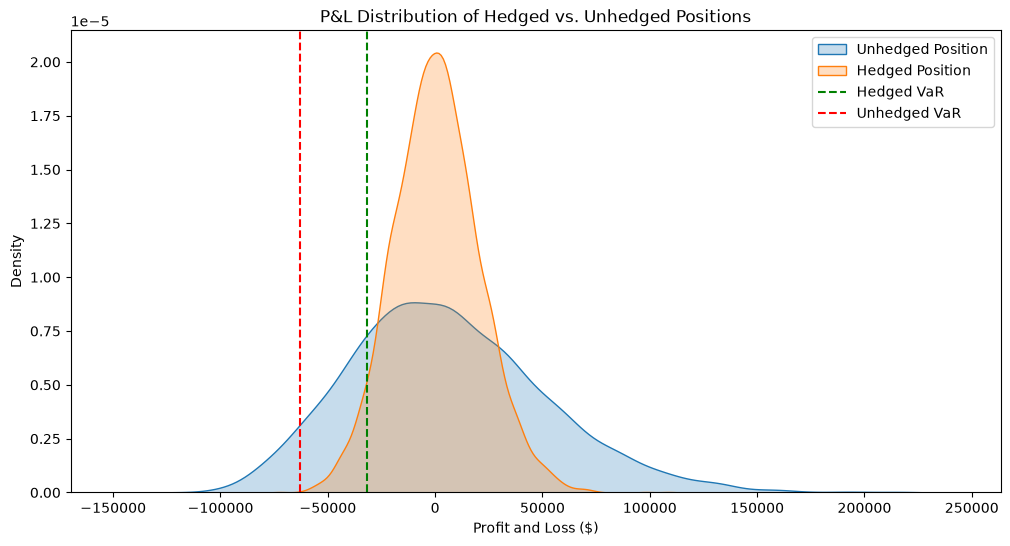

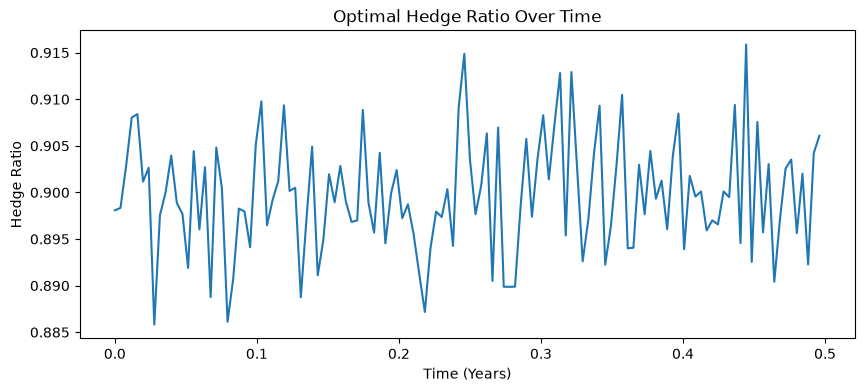

In [44]:
plt.figure(figsize=(12,6))
sns.kdeplot(pnl_unhedged, label = 'Unhedged Position', fill = True)
sns.kdeplot(pnl_hedged, label = 'Hedged Position', fill = True)
plt.axvline(-VaR_hedged, label = "Hedged VaR", color = "Green", linestyle = "--")
plt.axvline(-VaR_unhedged, label = "Unhedged VaR", color = "Red", linestyle = "--")
plt.title('P&L Distribution of Hedged vs. Unhedged Positions')
plt.xlabel('Profit and Loss ($)')
plt.ylabel('Density')
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(np.arange(N_steps) * dt, hedge_ratios)
plt.title('Optimal Hedge Ratio Over Time')
plt.xlabel('Time (Years)')
plt.ylabel('Hedge Ratio')
plt.show()

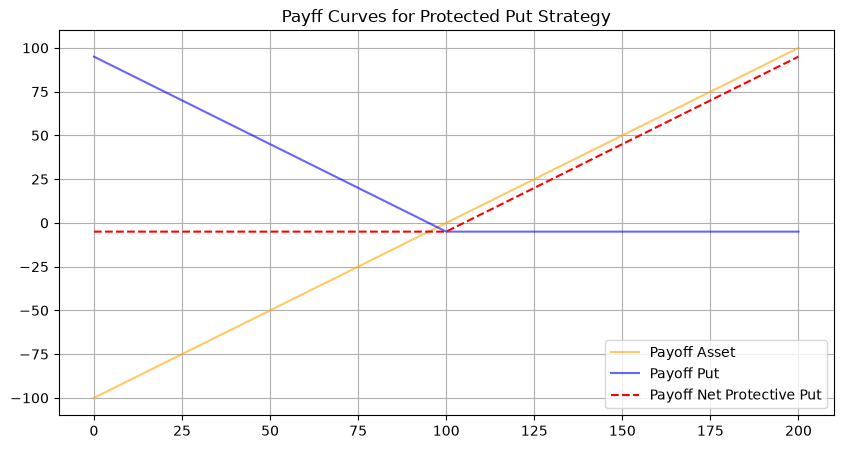

In [58]:
# Protecive Put Strategy

S0 = 100
K = 100
put_premium = 5

S_T = np.linspace(0, 200, 201)

payoff_asset = S_T - S0
payoff_put = np.maximum(K - S_T , 0) - put_premium

payoff_protective_put = payoff_asset + payoff_put

plt.figure(figsize=(10,5))
plt.plot(
    payoff_asset,
    label = "Payoff Asset",
    color = "Orange",
    alpha = 0.6
)

plt.plot(
    payoff_put,
    label = "Payoff Put",
    color = "Blue",
    alpha = 0.6
)

plt.plot(
    payoff_protective_put,
    label = "Payoff Net Protective Put",
    color = "Red",
    linestyle = "--"
)

plt.title('Payff Curves for Protected Put Strategy')
plt.legend()
plt.grid()
plt.show()



In [59]:

from scipy.stats import norm
# Implementing Protective put using black scholes
np.random.seed(42)
S0 = 100
K = 100
T = 0.5
r = 0.02
sigma = 0.25
mu = 0.10
N_simulations = 5000
N_steps = 126

dt = T / N_steps
Q = 2000
q = 100
N_options = Q//q

def black_scholes(S, K, T, r, sigma):
    d1 = (np.log(S/K) + (r + 0.5*sigma ** 2)* T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    put_price = K * np.exp(-r * T) * norm.cdf(-d2) - S* norm.cdf(-d1)

    return put_price


put_premium = black_scholes(S0, K, T, r, sigma)
total_premium = put_premium * N_options * q

print(f"Premium per option: {put_premium:.3f}")
print(f"Total Premium: {total_premium:.3f}")


Premium per option: 6.522
Total Premium: 13043.659


In [65]:
time_grid = np.linspace(0, T, N_steps+1)

S_path = np.zeros((N_simulations, N_steps + 1 ))
S_path[:, 0] = S0

for i in range(1, N_steps + 1):
    z = np.random.standard_normal(N_simulations)
    S_path[:, i] = S_path[:, i-1] * np.exp((mu - 0.5*sigma**2)*dt + sigma * z * np.sqrt(dt))

S_T = S_path[:, -1]

payoff_asset = Q * (S_T - S0)
payoff_put = N_options * q * np.maximum(K- S_T, 0 )

total_pnl = payoff_asset + payoff_put - total_premium

In [70]:
pnl_unhedged = payoff_asset

In [74]:
results = pd.DataFrame({
    "Asset_Price_T": S_T,
    'Payoff_Asset' : payoff_asset,
    'Payoff_Put' : payoff_put,
    'Total_PnL_Hedged' : total_pnl,
    'PnL_Unhedged' : pnl_unhedged
})

results[['Total_PnL_Hedged', 'PnL_Unhedged']].describe()


,Total_PnL_Hedged,PnL_Unhedged
count,5000.000000,5000.000000
mean,6655.277913,9558.104130
std,26671.412974,37031.641782
min,-13043.659498,-95722.711577
25%,-13043.659498,-17062.972605
50%,-5875.248445,7168.411053
75%,19187.942961,32231.602459
max,160585.730135,173629.389632


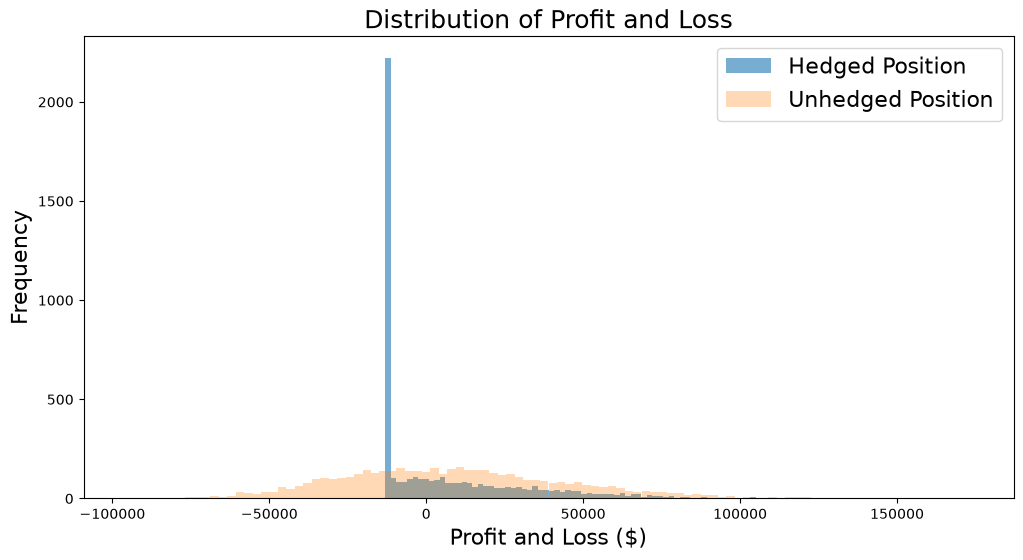

In [79]:
plt.figure(figsize=(12, 6))
plt.hist(total_pnl, bins=100, alpha=0.6, label='Hedged Position')
plt.hist(pnl_unhedged, bins=100, alpha=0.3, label='Unhedged Position')
plt.title('Distribution of Profit and Loss', fontsize=18)
plt.xlabel('Profit and Loss ($)', fontsize=16)
plt.ylabel('Frequency', fontsize=16)
plt.legend(fontsize=16)
plt.show()

In [77]:
total_pnl

array([  1901.72267018,  21624.20570207,  15349.47712458, ...,
       -13043.65949766,   6255.30832988, -13043.65949766], shape=(5000,))

In [92]:
# Covered call 

S0 = 100
K = 100
S_T = np.linspace(0,200, 201)
call_premium = 5

payoff_asset = S_T - S0
payoff_call = call_premium - np.maximum(S_T - K, 0) 

total_payoff = payoff_asset + payoff_call


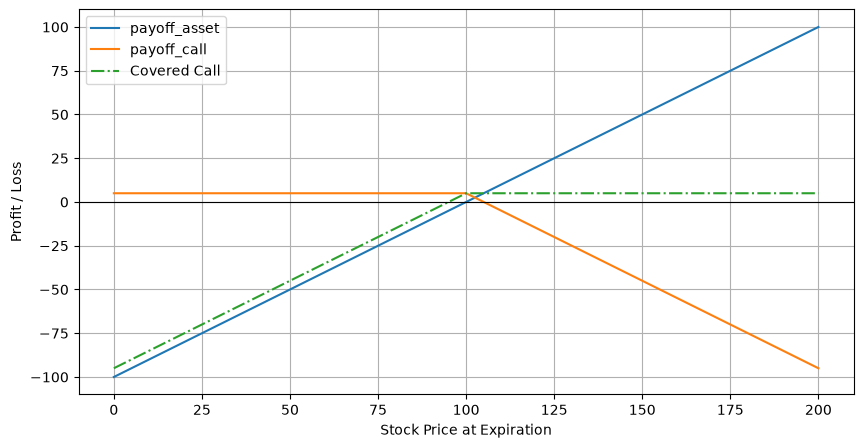

In [104]:
plt.figure(figsize = (10,5))
plt.plot(S_T, payoff_asset, label = "payoff_asset")
plt.plot(S_T, payoff_call, label = "payoff_call")
plt.plot(S_T, total_payoff, label="Covered Call", linestyle = "-.")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Stock Price at Expiration")
plt.ylabel("Profit / Loss")
plt.legend()
plt.grid(True)
plt.show()